**ANOMALY DETECTION OC-SVM**

In [17]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [54]:
flood = 30
jobs = [
    ("ocsvm", f"net_v3_{flood}per_w_v2"),
    ("ocsvm", f"attn_{flood}per_w"),
    ("md", f"net_v3_{flood}per_v2"),
    ("md", f"attn_{flood}per"),
]

def load_job(metodo, job_name):
    results_dir = f"/tmp/anomaly_results_{metodo}_{job_name}"      
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_{metodo}_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []
all_rules = {}

for metodo, job_name in jobs:
    results, df = load_job(metodo, job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "metodo": metodo,
        "job_name": job_name,
        "min_flood_area": results.get("min_flood_area"),
        "n_fit": results.get("n_fit"), "n_thr": results.get("n_thr"), "n_normali": results.get("n_normali"), "n_anomale": results.get("n_anomale"),
        "score_normali": f"{score_normal.mean():.2f} ± {score_normal.std():.2f}",
        "score_anomale": f"{score_anom.mean():.2f} ± {score_anom.std():.2f}",
        "auroc": results.get("auroc"),   
    })
    all_rules[(metodo, job_name)] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index(["metodo", "job_name"])
df_rules = pd.concat(all_rules, names=["metodo", "job_name", "regola"])

df_summary

min_flood_area  n_fit  n_thr  n_normali  n_anomale  \
metodo job_name                                                                
ocsvm  net_v3_30per_w_v2            30.0   2072    500        815        815   
       attn_30per_w                 30.0   2072    500        815        815   
md     net_v3_30per_v2              30.0   2072    500        815        815   
       attn_30per                   30.0   2072    500        815        815   

                             score_normali      score_anomale     auroc  
metodo job_name                                                          
ocsvm  net_v3_30per_w_v2       1.21 ± 1.43       -0.80 ± 1.38  0.850195  
       attn_30per_w            1.14 ± 0.95       -0.05 ± 1.00  0.817056  
md     net_v3_30per_v2    -293.60 ± 161.94   -434.68 ± 174.71  0.850116  
       attn_30per         -351.59 ± 867.89  -851.91 ± 3765.52  0.813638

In [55]:
df_rules

soglia     TP     FP     FN     TN  \
metodo job_name          regola                                           
ocsvm  net_v3_30per_w_v2 FA 5%    -1.621194  223.0   32.0  592.0  783.0   
                         FA 10%   -0.670833  438.0   68.0  377.0  747.0   
                         FA 15%   -0.281156  522.0  111.0  293.0  704.0   
                         FA 20%    0.059512  595.0  159.0  220.0  656.0   
                         FA 25%    0.389950  652.0  206.0  163.0  609.0   
                         FA 30%    0.594179  673.0  237.0  142.0  578.0   
       attn_30per_w      FA 5%    -1.048338  179.0   36.0  636.0  779.0   
                         FA 10%   -0.401145  295.0   72.0  520.0  743.0   
                         FA 15%    0.026913  392.0  110.0  423.0  705.0   
                         FA 20%    0.426357  503.0  152.0  312.0  663.0   
                         FA 25%    0.687241  586.0  195.0  229.0  620.0   
                         FA 30%    0.837551  626.0  236.0  189.0  579.0   
md     net_v3_30per_v2   FA 5%  -488.132888  197.0   32.0  618.0  783.0   
                         FA 10% -394.072959  422.0   64.0  393.0  751.0   
                         FA 15% -363.432358  512.0   99.0  303.0  716.0   
                         FA 20% -336.147755  602.0  161.0  213.0  654.0   
                         FA 25% -319.196318  642.0  206.0  173.0  609.0   
                         FA 30% -305.824734  674.0  235.0  141.0  580.0   
       attn_30per        FA 5%  -669.799061  182.0   39.0  633.0  776.0   
                         FA 10% -479.225855  285.0   72.0  530.0  743.0   
                         FA 15% -396.292162  382.0  106.0  433.0  709.0   
                         FA 20% -337.811405  487.0  150.0  328.0  665.0   
                         FA 25% -304.701176  572.0  191.0  243.0  624.0   
                         FA 30% -287.575288  616.0  230.0  199.0  585.0   

                                  FA_rate   MA_rate       REC      PREC  \
metodo job_name          regola                                           
ocsvm  net_v3_30per_w_v2 FA 5%   0.039264  0.726380  0.273620  0.874510   
                         FA 10%  0.083436  0.462577  0.537423  0.865613   
                         FA 15%  0.136196  0.359509  0.640491  0.824645   
                         FA 20%  0.195092  0.269939  0.730061  0.789125   
                         FA 25%  0.252761  0.200000  0.800000  0.759907   
                         FA 30%  0.290798  0.174233  0.825767  0.739560   
       attn_30per_w      FA 5%   0.044172  0.780368  0.219632  0.832558   
                         FA 10%  0.088344  0.638037  0.361963  0.803815   
                         FA 15%  0.134969  0.519018  0.480982  0.780876   
                         FA 20%  0.186503  0.382822  0.617178  0.767939   
                         FA 25%  0.239264  0.280982  0.719018  0.750320   
                         FA 30%  0.289571  0.231902  0.768098  0.726218   
md     net_v3_30per_v2   FA 5%   0.039264  0.758282  0.241718  0.860262   
                         FA 10%  0.078528  0.482209  0.517791  0.868313   
                         FA 15%  0.121472  0.371779  0.628221  0.837971   
                         FA 20%  0.197546  0.261350  0.738650  0.788991   
                         FA 25%  0.252761  0.212270  0.787730  0.757075   
                         FA 30%  0.288344  0.173006  0.826994  0.741474   
       attn_30per        FA 5%   0.047853  0.776687  0.223313  0.823529   
                         FA 10%  0.088344  0.650307  0.349693  0.798319   
                         FA 15%  0.130061  0.531288  0.468712  0.782787   
                         FA 20%  0.184049  0.402454  0.597546  0.764521   
                         FA 25%  0.234356  0.298160  0.701840  0.749672   
                         FA 30%  0.282209  0.244172  0.755828  0.728132   

                                       F1  
metodo job_name          regola            
ocsvm  net_v3_30per_w_v2 FA 5%   0.416822  
   

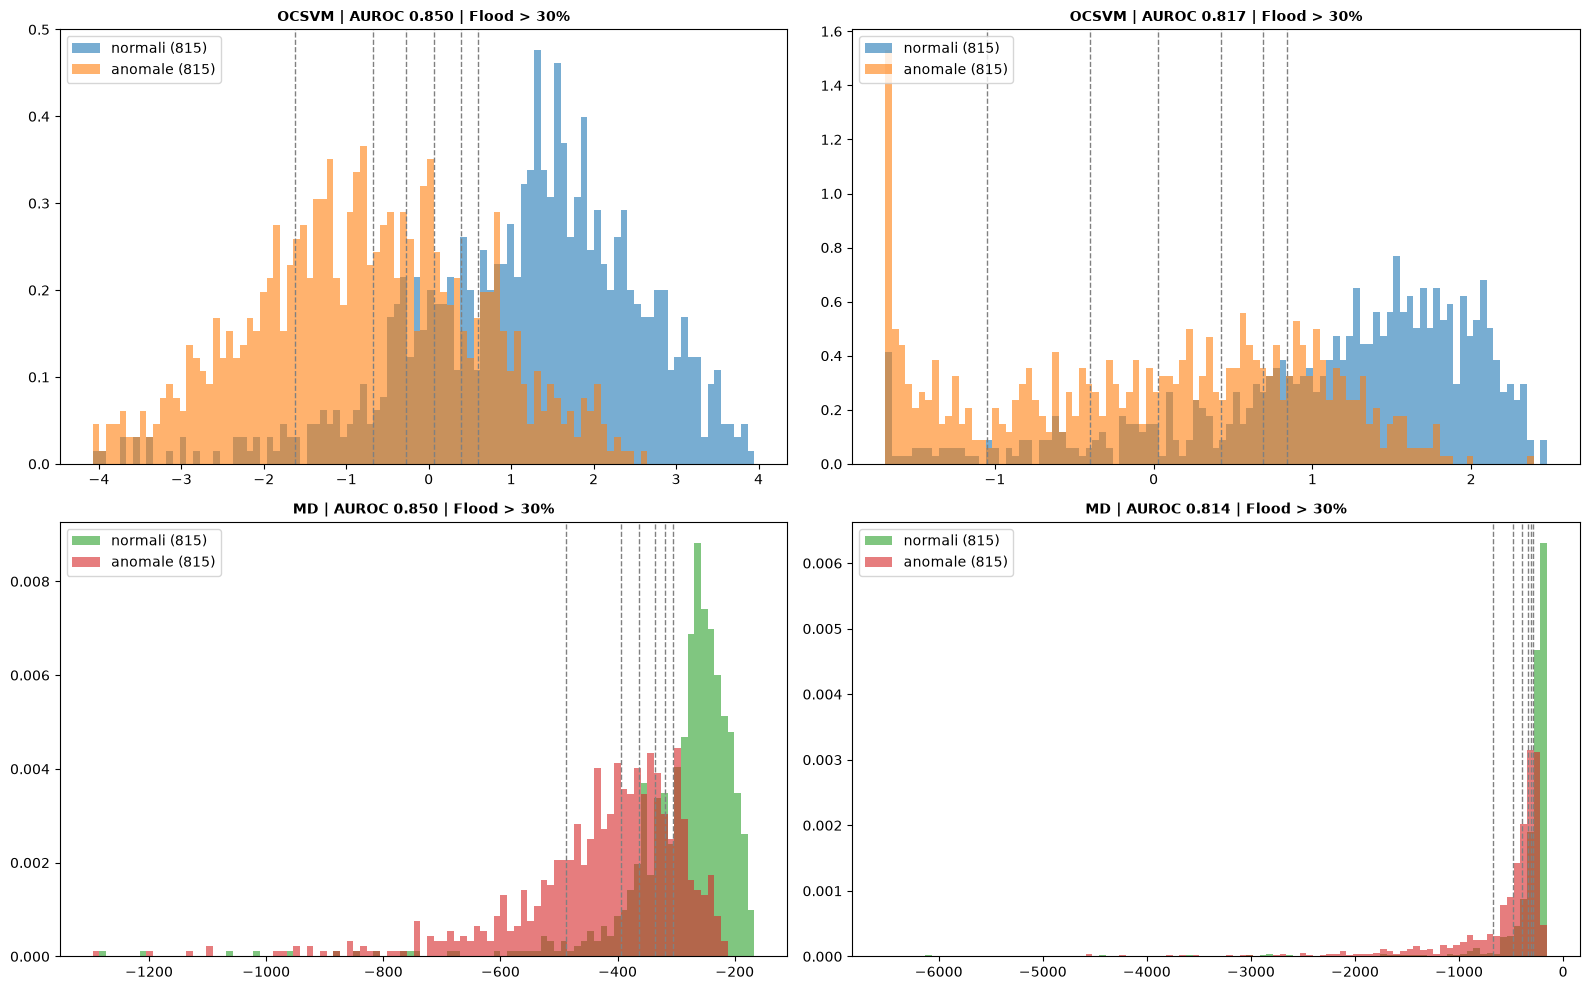

In [56]:
def plot_hist(ax, metodo, job_name, results, df, colori=("tab:blue", "tab:orange")):
    col_normal, col_anom = colori

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, color=col_normal, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, color=col_anom, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        etichetta = nome.split("(")[-1].rstrip(")")
        for chiave in ("soglia", "soglia_low", "soglia_high"):
            s = r.get(chiave)
            if s is not None and lo <= s <= hi:
                ax.axvline(x=s, color="gray", linestyle="--", linewidth=1)
                ax.text(s, ax.get_ylim()[1] * 0.97, "", rotation=90, va="top", ha="right", fontsize=8)

    auroc = results.get("auroc")
    ax.legend(loc="upper left")
    ax.set_title(f"{metodo.upper()} | AUROC {auroc:.3f} | Flood > {flood}%", fontsize=10, fontweight="bold")


n_cols = 2
n_rows = int(np.ceil(len(jobs) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

meta = len(jobs) // 2

for i, (ax, (metodo, job_name)) in enumerate(zip(axes.flat, jobs)):
    colori = ("tab:blue", "tab:orange") if i < meta else ("tab:green", "tab:red")
    results, df = load_job(metodo, job_name)
    plot_hist(ax, metodo, job_name, results, df, colori=colori)

for ax in axes.flat[len(jobs):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

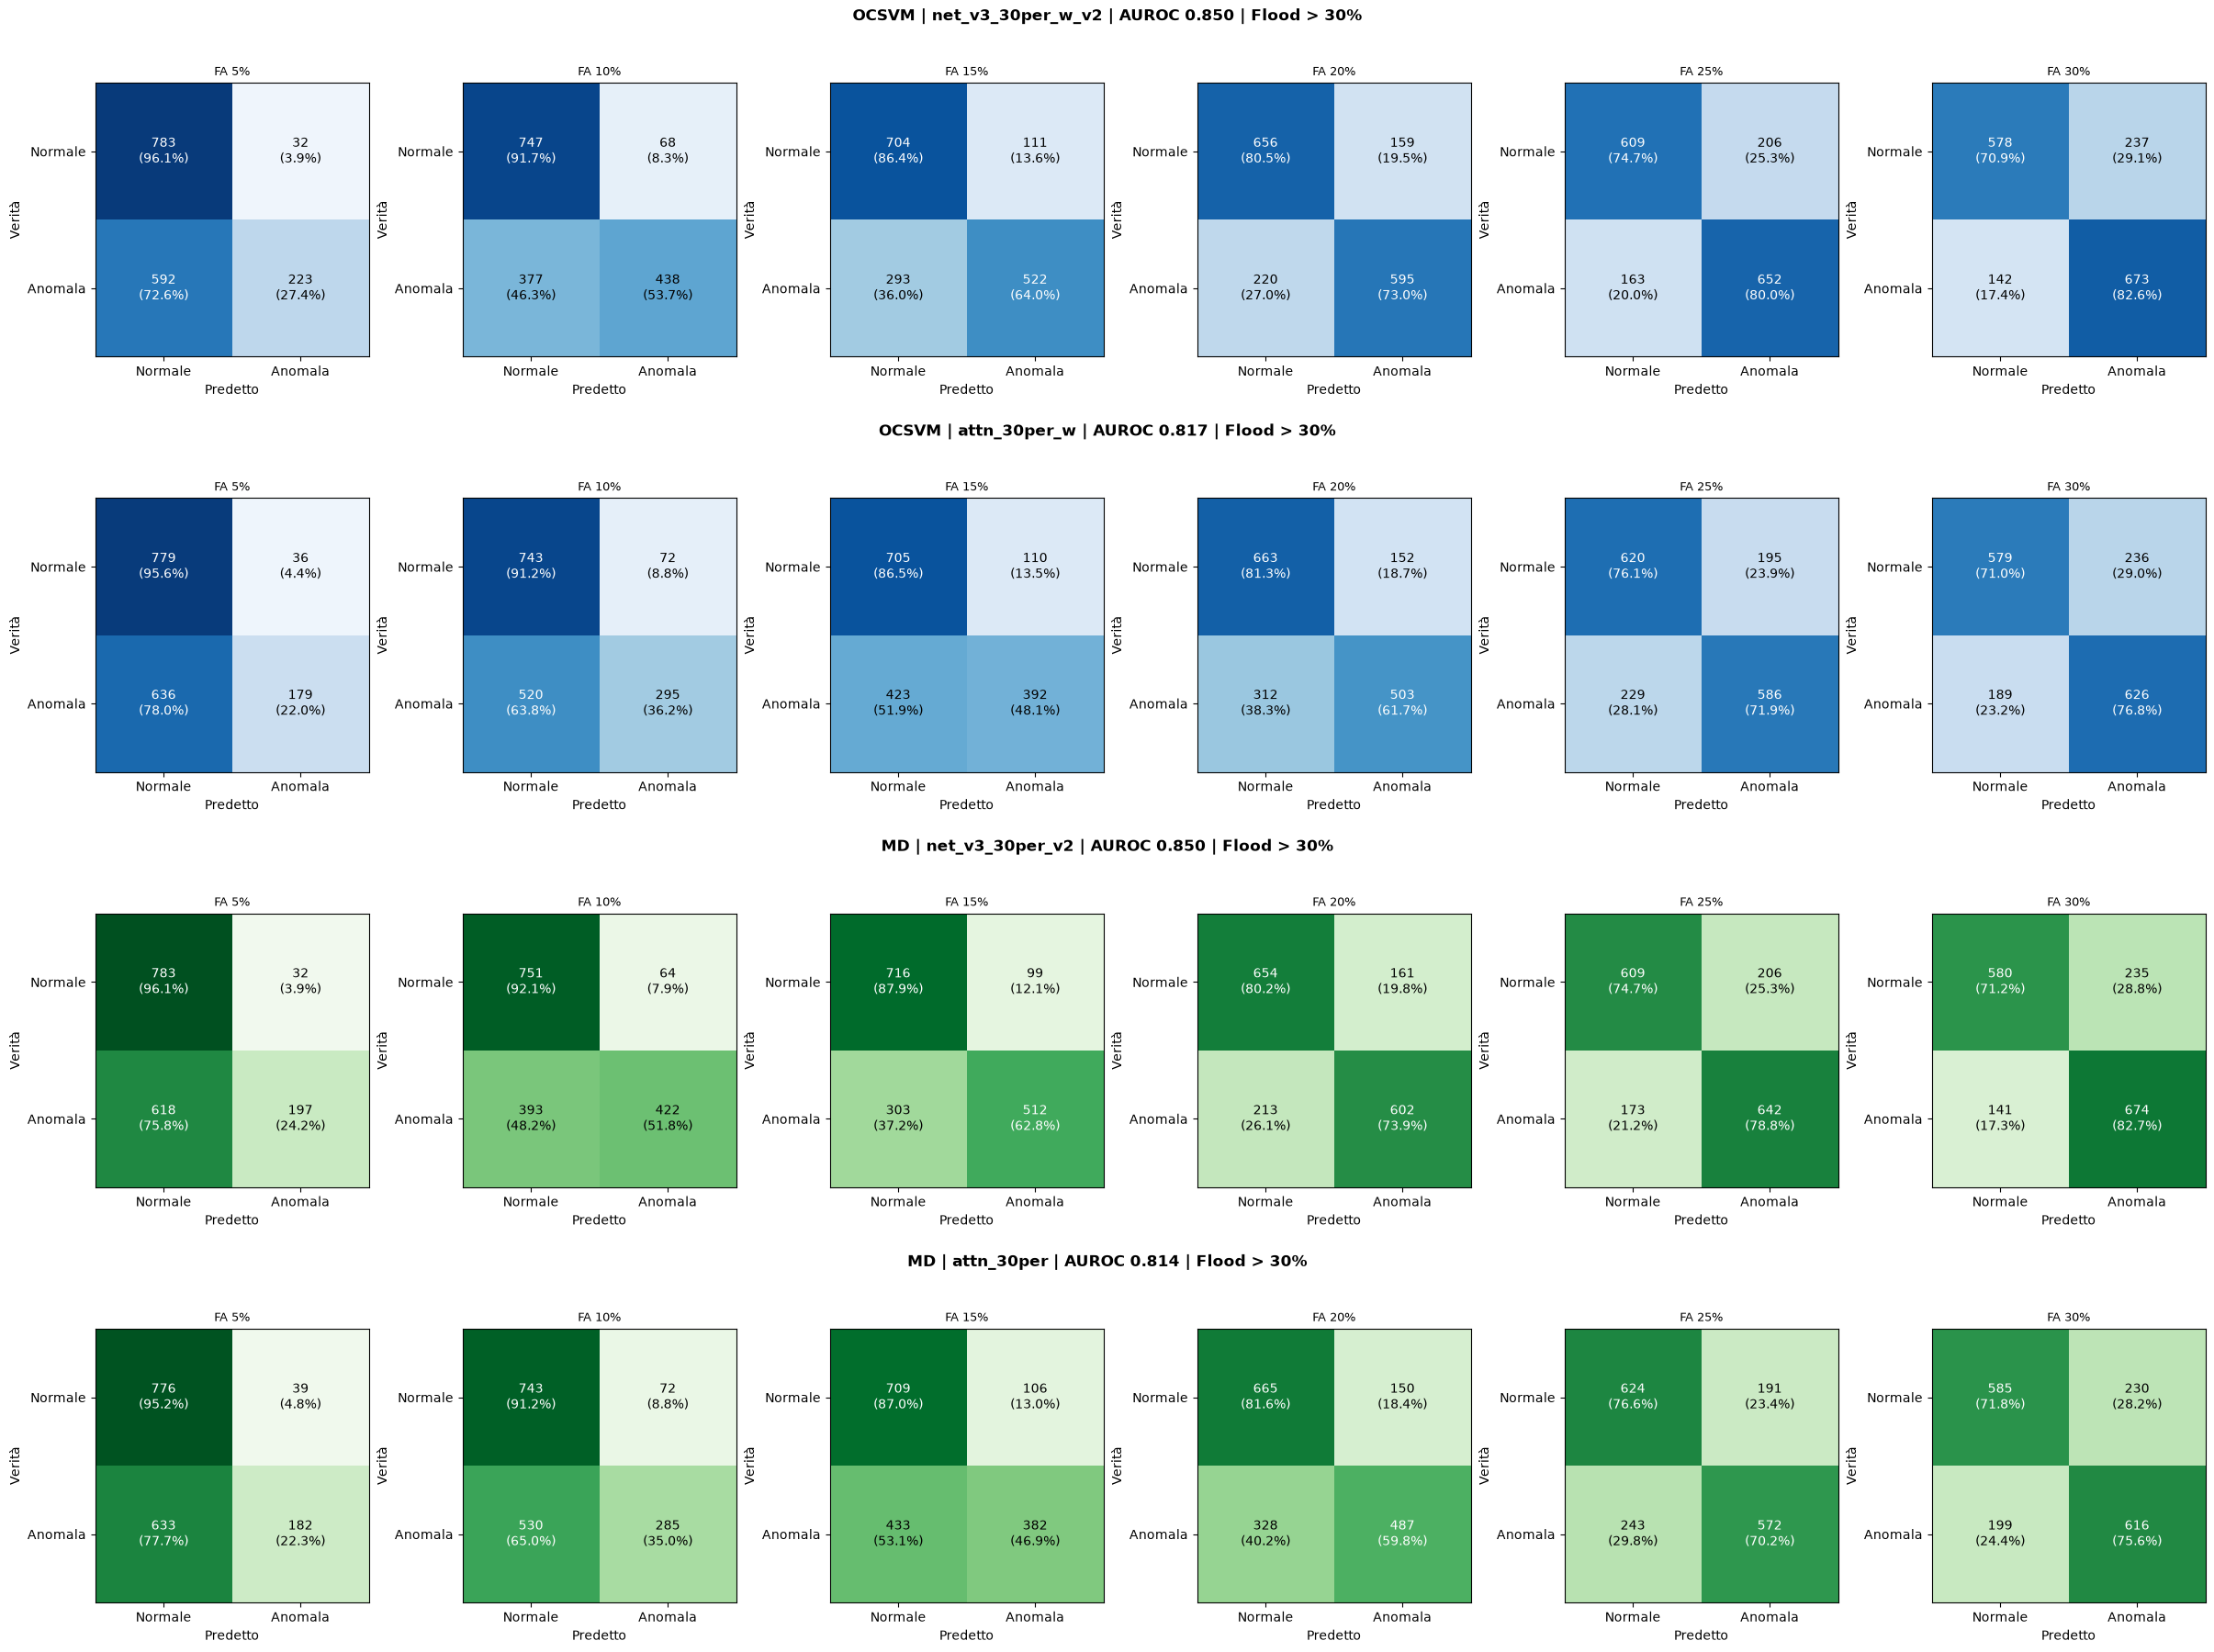

In [57]:
def plot_confusion_row(sfig, metodo, job_name, results, n_cols, cmap="Blues"):
    rules = results["rules"]
    auroc = results.get("auroc", results.get("auroc_cos_sim_low_anom"))
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap=cmap, vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"{metodo.upper()} | {job_name} | AUROC {auroc:.3f} | Flood > {flood:.0f}%", fontsize=12, fontweight="bold")


loaded = [(metodo, job_name, load_job(metodo, job_name)[0]) for metodo, job_name in jobs]
n_rows = len(loaded)
n_cols = max(len(res["rules"]) for _, _, res in loaded)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * n_rows), layout="constrained")
subfigs = fig.subfigures(n_rows, 1)

meta = n_rows // 2

for i, (sfig, (metodo, job_name, results)) in enumerate(zip(subfigs, loaded)):
    cmap = "Blues" if i < meta else "Greens"
    plot_confusion_row(sfig, metodo, job_name, results, n_cols, cmap=cmap)

plt.show()

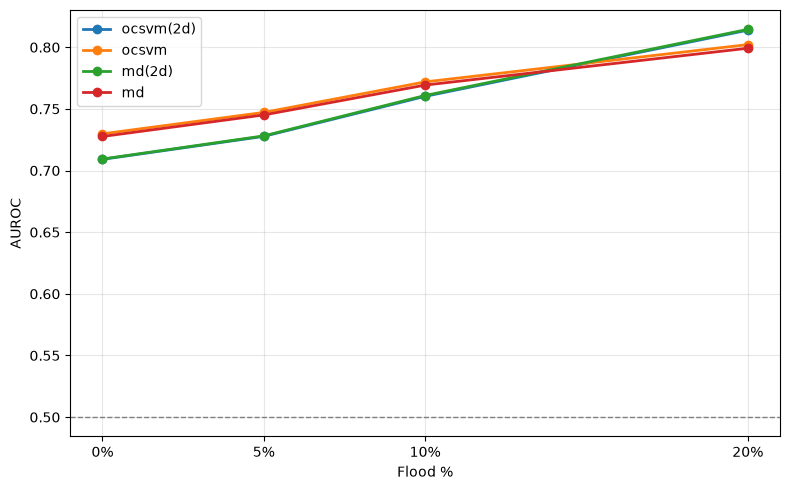

,ocsvm(2d),ocsvm,md(2d),md
min_flood_area,,,,
0,0.709084,0.729779,0.709341,0.727623
5,0.727715,0.747134,0.728111,0.745102
10,0.760172,0.771900,0.760864,0.769309
20,0.813847,0.802138,0.814490,0.799202


In [58]:
floods = [0, 5, 10, 20]

metodi = [
    ("ocsvm(2d)", "ocsvm", lambda f: f"net_v3_{f}per_w_v2"),
    ("ocsvm", "ocsvm", lambda f: f"attn_{f}per_w"),
    ("md(2d)", "md", lambda f: f"net_v3_{f}per_v2"),
    ("md", "md", lambda f: f"attn_{f}per"),
]

auroc_table = {}            
for etichetta, metodo, nome in metodi:
    valori = []
    for f in floods:
        try:
            results, _ = load_job(metodo, nome(f))
            valori.append(results.get("auroc"))
        except Exception as e:
            print(f"EXC -> {metodo}_{nome(f)}: {e}")
            valori.append(np.nan)                                
    auroc_table[etichetta] = valori

df_auroc = pd.DataFrame(auroc_table, index=floods)
df_auroc.index.name = "min_flood_area"

fig, ax = plt.subplots(figsize=(8, 5))
for etichetta in df_auroc.columns:
    ax.plot(df_auroc.index, df_auroc[etichetta], marker="o", linewidth=2, label=etichetta)

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)         
ax.set_xticks(floods)
ax.set_xticklabels([f"{f}%" for f in floods])
ax.set_xlabel("Flood %")
ax.set_ylabel("AUROC")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

df_auroc